# Student Performance Analysis
### HCL Data Analyst Training Project

**Name:** Jay Narayan Tiwari  
**Roll No:** 2026B01010438 
**College / Branch / Year:** ABES ENGINEERING COLLEGE / BTECH CSE / Ist year 
**Trainer:** Mr. Deepak Gautam  
**Date:** 21-11-2026

**Tools used:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook

## About the project
In this project I analysed the marks of 200 first year students. The data has four subject marks, attendance, daily study hours and an assignment score. First I cleaned the raw file, then I made some new columns and tried to answer four questions with tables and charts.

**Note:** The data is made up (synthetic) for practice. It is not the record of any real student. The pass rule I used is my own assumption (see Step 12), it is not an official college rule.

## The four questions
1. Which subject has the highest average marks?
2. How many students passed and how many failed?
3. How do the average marks change with attendance?
4. Do students who study more hours get more marks?

## Assumptions I made
- Marks and assignment score are out of 100, attendance is in percent and study hours are per day.
- Pass means 40 or more marks in each of the four subjects.
- Missing numbers are filled with the median and missing Section / Gender with the most common value.
- Values outside the valid range (for example attendance above 100) are treated as wrong and made missing first.

## Step 1: Importing libraries
Pandas is for the table (DataFrame), NumPy is for some number work and Matplotlib is for the charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 2: Loading the raw data
The csv file is inside the `Data/Raw_data` folder. This notebook is inside the `Notebook` folder, so I use `../` to go one folder back.

In [2]:
df = pd.read_csv("../Data/Raw_data/student_performance_raw.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (203, 10)


,Student_ID,Section,Gender,Attendance_Percentage,Daily_Study_Hours,Maths_Marks,Science_Marks,English_Marks,Computer_Marks,Assignment_Score
0,STU001,D,Male,75.0,2.2,35.0,43.0,51.0,52.0,47.0
1,STU002,A,Male,85.0,2.7,59.0,73.0,77.0,75.0,75.0
2,STU003,a,Female,74.0,2.2,45.0,60.0,60.0,78.0,83.0
3,STU004,C,Male,82%,4.5,60.0,69.0,60.0,85.0,78.0
4,STU005,D,Male,89.0,3.0,69.0,69.0,80.0,65.0,69.0


## Step 3: Looking at the data first
Before cleaning I want to see the column names, data types, missing values and basic statistics.

In [3]:
print(df.columns.tolist())
print()
df.info()

['Student_ID', 'Section', 'Gender', 'Attendance_Percentage', 'Daily_Study_Hours', 'Maths_Marks', 'Science_Marks', 'English_Marks', 'Computer_Marks', 'Assignment_Score']

<class 'pandas.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             203 non-null    str    
 1   Section                202 non-null    str    
 2   Gender                 202 non-null    str    
 3   Attendance_Percentage  198 non-null    str    
 4   Daily_Study_Hours      200 non-null    str    
 5   Maths_Marks            200 non-null    str    
 6   Science_Marks          201 non-null    str    
 7   English_Marks          203 non-null    float64
 8   Computer_Marks         202 non-null    float64
 9   Assignment_Score       200 non-null    float64
dtypes: float64(3), str(7)
memory usage: 16.0 KB


In [4]:
df.describe()

,English_Marks,Computer_Marks,Assignment_Score
count,203.000000,202.000000,200.000000
mean,59.216749,67.193069,62.965000
std,13.045705,67.096258,13.342936
min,-10.000000,27.000000,19.000000
25%,51.000000,54.250000,55.000000
50%,60.000000,63.000000,63.000000
75%,69.000000,71.000000,72.000000
max,85.000000,999.000000,100.000000


In [5]:
# missing values in each column
df.isnull().sum()

Student_ID               0
Section                  1
Gender                   1
Attendance_Percentage    5
Daily_Study_Hours        3
Maths_Marks              3
Science_Marks            2
English_Marks            0
Computer_Marks           1
Assignment_Score         3
dtype: int64

**What I noticed:**
- `Attendance_Percentage`, `Daily_Study_Hours`, `Maths_Marks` and `Science_Marks` are shown as text (`object` or `str`) and not as numbers. So some cells in these columns must have text like `%`, `hrs` or `absent`.
- Some columns have missing values.
- Rows = 203 but I expect 200 students, so there may be duplicates.

## Step 4: Checking duplicate rows

In [6]:
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicate rows: 3


,Student_ID,Section,Gender,Attendance_Percentage,Daily_Study_Hours,Maths_Marks,Science_Marks,English_Marks,Computer_Marks,Assignment_Score
15,STU016,C,Female,76.0,2.0,39.0,43.0,47.0,57.0,42.0
48,STU049,A,Male,69.0,4.9,59.0,44.0,73.0,68.0,80.0
130,STU131,A,Female,73.0,1.6,50.0,38.0,47.0,36.0,37.0
200,STU016,C,Female,76.0,2.0,39.0,43.0,47.0,57.0,42.0
201,STU049,A,Male,69.0,4.9,59.0,44.0,73.0,68.0,80.0
202,STU131,A,Female,73.0,1.6,50.0,38.0,47.0,36.0,37.0


## Step 5: Removing the duplicates
Only the rows which are exactly the same are removed. The first copy is kept.

In [7]:
rows_before = len(df)
df = df.drop_duplicates().copy()

print("Rows before:", rows_before)
print("Rows after:", len(df))

Rows before: 203
Rows after: 200


## Step 6: Cleaning the text columns (Section and Gender)
Let me check how many different values are there.

In [8]:
print(df["Section"].value_counts(dropna=False))
print()
print(df["Gender"].value_counts(dropna=False))

Section
D      59
A      52
B      43
C      41
 a      1
NaN     1
B       1
c       1
 d      1
Name: count, dtype: int64

Gender
Male       122
Female      72
M            1
male         1
F            1
FEMALE       1
NaN          1
 female      1
Name: count, dtype: int64


`Section` has extra spaces and small letters (like ` a`, `B `). `Gender` is written in many ways (`M`, `male`, `FEMALE`). I will remove the spaces, make everything lowercase and then use a dictionary to map to one standard word.

In [9]:
df["Section"] = df["Section"].str.strip().str.upper()

gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female"
}
df["Gender"] = df["Gender"].str.strip().str.lower().map(gender_map)

print(df["Section"].value_counts(dropna=False))
print()
print(df["Gender"].value_counts(dropna=False))

Section
D      60
A      53
B      44
C      42
NaN     1
Name: count, dtype: int64

Gender
Male      124
Female     75
NaN         1
Name: count, dtype: int64


## Step 7: Fixing the number columns
Some cells have text like `82%`, `3 hrs` or `absent`. I remove `%` and `hrs` first. After that `pd.to_numeric(errors="coerce")` changes the numbers properly and the cells which are still text (like `absent`) become NaN (missing).

In [10]:
df["Attendance_Percentage"] = df["Attendance_Percentage"].astype(str).str.replace("%", "", regex=False)
df["Daily_Study_Hours"] = df["Daily_Study_Hours"].astype(str).str.replace("hrs", "", regex=False)

number_cols = ["Attendance_Percentage", "Daily_Study_Hours", "Maths_Marks", "Science_Marks",
               "English_Marks", "Computer_Marks", "Assignment_Score"]

for col in number_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dtypes

Student_ID                   str
Section                      str
Gender                       str
Attendance_Percentage    float64
Daily_Study_Hours        float64
Maths_Marks              float64
Science_Marks            float64
English_Marks            float64
Computer_Marks           float64
Assignment_Score         float64
dtype: object

## Step 8: Finding impossible values
I made these rules for the project:
- attendance must be between 0 and 100
- study hours per day must be between 0 and 12
- marks and assignment score must be between 0 and 100

Values outside this range are wrong, so I change them to NaN.

In [11]:
df.describe().loc[["min", "max"]]

,Attendance_Percentage,Daily_Study_Hours,Maths_Marks,Science_Marks,English_Marks,Computer_Marks,Assignment_Score
min,-20.0,-2.0,26.0,17.0,-10.0,27.0,19.0
max,125.0,18.0,150.0,90.0,85.0,999.0,100.0


In [12]:
df.loc[~df["Attendance_Percentage"].between(0, 100), "Attendance_Percentage"] = np.nan
df.loc[~df["Daily_Study_Hours"].between(0, 12), "Daily_Study_Hours"] = np.nan

mark_cols = ["Maths_Marks", "Science_Marks", "English_Marks", "Computer_Marks", "Assignment_Score"]
for col in mark_cols:
    df.loc[~df[col].between(0, 100), col] = np.nan

print("Missing values now:")
df.isnull().sum()

Missing values now:


Student_ID               0
Section                  1
Gender                   1
Attendance_Percentage    7
Daily_Study_Hours        5
Maths_Marks              6
Science_Marks            3
English_Marks            1
Computer_Marks           2
Assignment_Score         3
dtype: int64

## Step 9: Filling the missing values
I did not delete these rows because that would reduce the data. For number columns I fill with the **median** (the middle value). I used median because it is not changed much by very high or very low values. For `Section` and `Gender` I use the most common value (mode).

In a real project I would ask the data owner before filling like this.

In [13]:
missing_before = df.isnull().sum()
print("Missing values before filling:")
print(missing_before[missing_before > 0])
print("Total:", missing_before.sum())

for col in number_cols:
    df[col] = df[col].fillna(df[col].median())

df["Section"] = df["Section"].fillna(df["Section"].mode()[0])
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

print("Total missing values left:", df.isnull().sum().sum())
print("Duplicates left:", df.duplicated().sum())
print("Shape of cleaned data:", df.shape)

Missing values before filling:
Section                  1
Gender                   1
Attendance_Percentage    7
Daily_Study_Hours        5
Maths_Marks              6
Science_Marks            3
English_Marks            1
Computer_Marks           2
Assignment_Score         3
dtype: int64
Total: 29
Total missing values left: 0
Duplicates left: 0
Shape of cleaned data: (200, 10)


**Cleaning summary:** 203 rows became 200 rows (3 duplicates removed). 29 missing values were filled (27 numbers with median, 1 Section and 1 Gender with mode). Most of these came from text like `absent` and from impossible values that I changed to missing in Step 8.

## Step 10: Making new columns
There are 4 subjects, each out of 100. So total marks is out of 400 and average marks is out of 100.

In [14]:
subjects = ["Maths_Marks", "Science_Marks", "English_Marks", "Computer_Marks"]

df["Total_Marks"] = df[subjects].sum(axis=1)
df["Average_Marks"] = (df["Total_Marks"] / 4).round(2)

df[["Student_ID", "Total_Marks", "Average_Marks"]].head()

,Student_ID,Total_Marks,Average_Marks
0,STU001,181.0,45.25
1,STU002,284.0,71.00
2,STU003,243.0,60.75
3,STU004,274.0,68.50
4,STU005,283.0,70.75


## Step 11: Pass / Fail column
**My assumption:** a student is Pass only if he/she has at least 40 marks in **all four** subjects. If even one subject is below 40 then the result is Fail.

In [15]:
df["Result"] = np.where((df[subjects] >= 40).all(axis=1), "Pass", "Fail")

df[["Student_ID"] + subjects + ["Result"]].head()

,Student_ID,Maths_Marks,Science_Marks,English_Marks,Computer_Marks,Result
0,STU001,35.0,43.0,51.0,52.0,Fail
1,STU002,59.0,73.0,77.0,75.0,Pass
2,STU003,45.0,60.0,60.0,78.0,Pass
3,STU004,60.0,69.0,60.0,85.0,Pass
4,STU005,69.0,69.0,80.0,65.0,Pass


## Step 12: Making groups for attendance and study hours
Groups make it easier to compare.

In [16]:
df["Attendance_Group"] = pd.cut(df["Attendance_Percentage"],
                                bins=[0, 70, 85, 100],
                                labels=["Below 70%", "70-85%", "Above 85%"],
                                include_lowest=True)

df["Study_Group"] = pd.cut(df["Daily_Study_Hours"],
                           bins=[0, 2, 4, 12],
                           labels=["Below 2 hrs", "2-4 hrs", "Above 4 hrs"],
                           include_lowest=True)

df[["Student_ID", "Attendance_Percentage", "Attendance_Group", "Daily_Study_Hours", "Study_Group"]].head()

,Student_ID,Attendance_Percentage,Attendance_Group,Daily_Study_Hours,Study_Group
0,STU001,75.0,70-85%,2.2,2-4 hrs
1,STU002,85.0,70-85%,2.7,2-4 hrs
2,STU003,74.0,70-85%,2.2,2-4 hrs
3,STU004,82.0,70-85%,4.5,Above 4 hrs
4,STU005,89.0,Above 85%,3.0,2-4 hrs


## Step 13: Some overall numbers

In [17]:
total_students = df["Student_ID"].nunique()
class_avg = df["Average_Marks"].mean()

print("Total students:", total_students)
print("Class average marks:", round(class_avg, 2))
print("Highest average:", df["Average_Marks"].max())
print("Lowest average:", df["Average_Marks"].min())
print("Average attendance:", round(df["Attendance_Percentage"].mean(), 1), "%")
print("Average study hours per day:", round(df["Daily_Study_Hours"].mean(), 1))

Total students: 200
Class average marks: 57.98
Highest average: 89.5
Lowest average: 28.25
Average attendance: 74.2 %
Average study hours per day: 3.2


## Question 1: Which subject has the highest average marks?

In [18]:
subject_avg = df[subjects].mean().sort_values(ascending=False).round(2)
print(subject_avg)

print()
print("Highest:", subject_avg.idxmax())
print("Lowest:", subject_avg.idxmin())

Computer_Marks    62.70
English_Marks     59.62
Maths_Marks       56.14
Science_Marks     53.48
dtype: float64

Highest: Computer_Marks
Lowest: Science_Marks


**What I notice:** Computer is the strongest subject and Science is the weakest. The gap between them is about 9 marks.

## Question 2: How many students passed and failed?

In [19]:
result_count = df["Result"].value_counts()
print(result_count)

print()
print("Pass percentage:", round(result_count["Pass"] / len(df) * 100, 1), "%")

Result
Pass    164
Fail     36
Name: count, dtype: int64

Pass percentage: 82.0 %


**What I notice:** Most students pass (82%). Since one low subject is enough to fail, some failed students may still have a good average in the other subjects.

## Question 3: Attendance and average marks
I compare the average marks of the three attendance groups. I also find the correlation (a number between -1 and 1 which tells how two columns move together).

In [20]:
attendance_summary = df.groupby("Attendance_Group", observed=False)["Average_Marks"].agg(["count", "mean"]).round(2)
attendance_summary.columns = ["Students", "Average_Marks"]
print(attendance_summary)

print()
print("Correlation (attendance and average marks):", round(df["Attendance_Percentage"].corr(df["Average_Marks"]), 2))

                  Students  Average_Marks
Attendance_Group                         
Below 70%               72          53.31
70-85%                  88          58.43
Above 85%               40          65.41

Correlation (attendance and average marks): 0.45


**What I notice:** The average marks go up with every attendance group, from 53.3 to 65.4. The correlation is moderate, so attendance is not the only reason.

## Question 4: Study hours and average marks

In [21]:
study_summary = df.groupby("Study_Group", observed=False)["Average_Marks"].agg(["count", "mean"]).round(2)
study_summary.columns = ["Students", "Average_Marks"]
print(study_summary)

print()
print("Correlation (study hours and average marks):", round(df["Daily_Study_Hours"].corr(df["Average_Marks"]), 2))

             Students  Average_Marks
Study_Group                         
Below 2 hrs        40          50.04
2-4 hrs           107          57.88
Above 4 hrs        53          64.18

Correlation (study hours and average marks): 0.5


**What I notice:** The pattern is similar to attendance. More study hours usually means higher marks, but the scatter plot later shows that many students are far from the trend.

## Extra analysis: Section and Gender
I also wanted to see if section or gender makes any difference.

In [22]:
section_summary = df.groupby("Section")["Average_Marks"].mean().round(2)
gender_summary = df.groupby("Gender")["Average_Marks"].mean().round(2)

print(section_summary)
print()
print(gender_summary)

Section
A    57.50
B    59.40
C    59.26
D    56.50
Name: Average_Marks, dtype: float64

Gender
Female    57.43
Male      58.32
Name: Average_Marks, dtype: float64


## Extra analysis: Assignment score
I had not used `Assignment_Score` yet, so I checked how it is related to average marks.

In [23]:
print("Correlation (assignment score and average marks):", round(df["Assignment_Score"].corr(df["Average_Marks"]), 2))

Correlation (assignment score and average marks): 0.78


**What I notice:** The correlation is high (about 0.78). Students who do well in the assignment also do well in exams. This is expected because assignment marks usually follow the same subject knowledge.

## Extra analysis: Top 10 students and students who need support
Students who failed (below 40 in at least one subject) are kept in a separate list so that a mentor can help them.

In [24]:
top_10 = df.sort_values("Average_Marks", ascending=False).head(10)
top_10[["Student_ID", "Section", "Attendance_Percentage", "Daily_Study_Hours", "Average_Marks"]]

,Student_ID,Section,Attendance_Percentage,Daily_Study_Hours,Average_Marks
122,STU123,B,100.0,4.3,89.50
138,STU139,C,77.0,4.5,80.25
68,STU069,C,100.0,4.8,79.50
154,STU155,D,72.0,5.9,79.25
163,STU164,B,75.0,4.7,78.00
119,STU120,C,86.0,3.4,76.50
190,STU191,A,82.0,4.1,76.25
18,STU019,D,93.0,3.3,76.25
28,STU029,C,70.0,5.9,74.75
170,STU171,A,96.0,3.3,74.75


In [25]:
need_support = df[df["Result"] == "Fail"].sort_values("Average_Marks")

print("Students who failed:", len(need_support))
print("Their average attendance:", round(need_support["Attendance_Percentage"].mean(), 1), "%")
print("Average attendance of all students:", round(df["Attendance_Percentage"].mean(), 1), "%")

need_support[["Student_ID", "Section", "Attendance_Percentage", "Daily_Study_Hours", "Average_Marks"]].head(10)

Students who failed: 36
Their average attendance: 64.4 %
Average attendance of all students: 74.2 %


,Student_ID,Section,Attendance_Percentage,Daily_Study_Hours,Average_Marks
174,STU175,D,57.0,0.6,28.25
195,STU196,D,66.0,1.3,31.25
116,STU117,A,61.0,0.6,33.75
94,STU095,B,64.0,2.2,36.00
57,STU058,B,75.0,2.3,37.00
92,STU093,C,84.0,1.4,38.25
89,STU090,D,68.0,1.4,38.25
166,STU167,A,55.0,2.2,38.75
75,STU076,A,79.0,2.8,39.00
29,STU030,C,63.0,0.3,39.25


## Charts
All charts are saved in the `Images` folder.

### Chart 1: Average marks of each subject

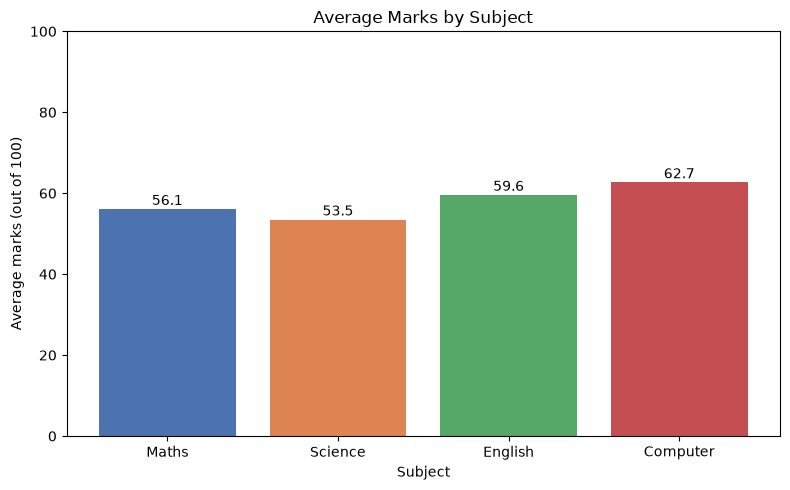

In [26]:
plt.figure(figsize=(8, 5))
plt.bar(["Maths", "Science", "English", "Computer"],
        df[subjects].mean().round(2),
        color=["#4c72b0", "#dd8452", "#55a868", "#c44e52"])
plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average marks (out of 100)")
plt.ylim(0, 100)

for i, v in enumerate(df[subjects].mean().round(1)):
    plt.text(i, v + 1, str(v), ha="center")

plt.tight_layout()
plt.savefig("../Images/01_subject_average_bar.png", dpi=150)
plt.show()

### Chart 2: Pass and Fail

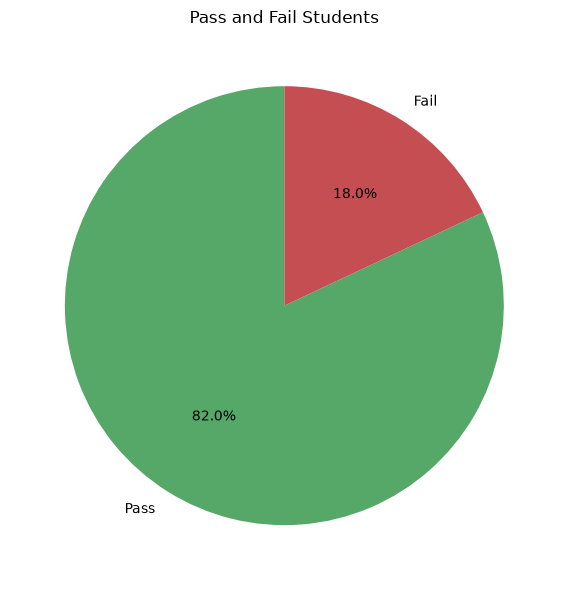

In [27]:
plt.figure(figsize=(6, 6))
plt.pie(result_count[["Pass", "Fail"]], labels=["Pass", "Fail"], autopct="%1.1f%%",
        colors=["#55a868", "#c44e52"], startangle=90)
plt.title("Pass and Fail Students")
plt.tight_layout()
plt.savefig("../Images/02_pass_fail_pie.png", dpi=150)
plt.show()

### Chart 3: Average marks for each attendance group

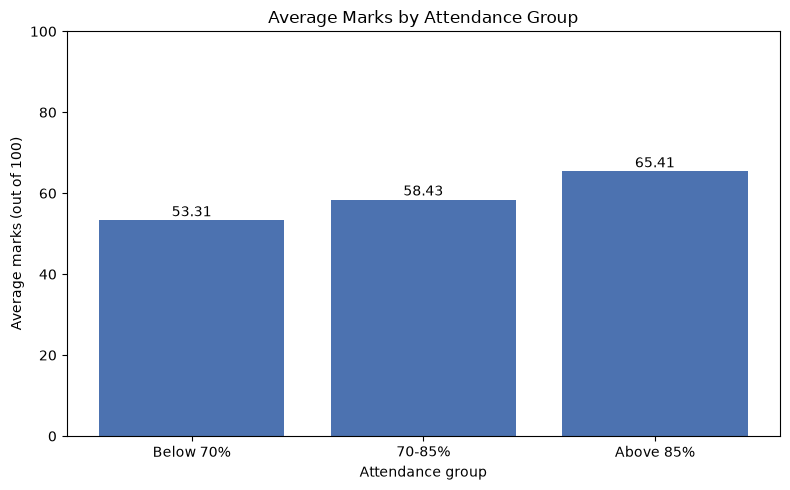

In [28]:
plt.figure(figsize=(8, 5))
plt.bar(attendance_summary.index.astype(str), attendance_summary["Average_Marks"], color="#4c72b0")
plt.title("Average Marks by Attendance Group")
plt.xlabel("Attendance group")
plt.ylabel("Average marks (out of 100)")
plt.ylim(0, 100)

for i, v in enumerate(attendance_summary["Average_Marks"]):
    plt.text(i, v + 1, str(v), ha="center")

plt.tight_layout()
plt.savefig("../Images/03_attendance_group_bar.png", dpi=150)
plt.show()

### Chart 4: Study hours vs average marks
Every dot is one student. The red line is the trend line.

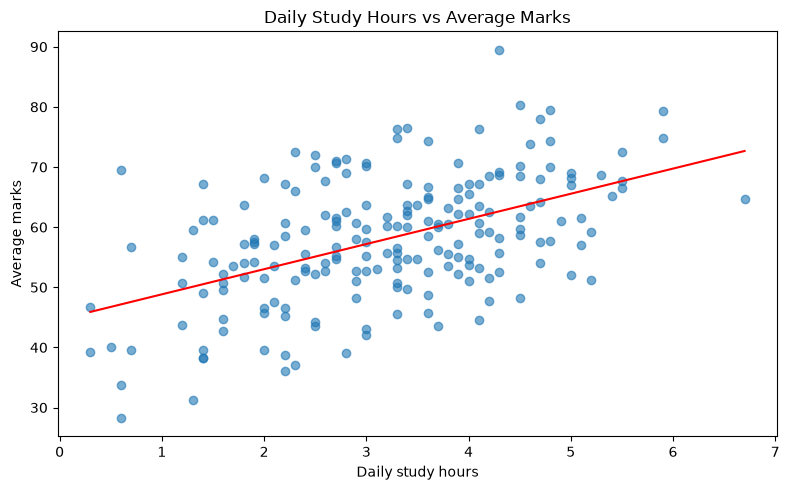

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Daily_Study_Hours"], df["Average_Marks"], alpha=0.6)

# trend line
m, c = np.polyfit(df["Daily_Study_Hours"], df["Average_Marks"], 1)
x = np.linspace(df["Daily_Study_Hours"].min(), df["Daily_Study_Hours"].max(), 50)
plt.plot(x, m * x + c, color="red")

plt.title("Daily Study Hours vs Average Marks")
plt.xlabel("Daily study hours")
plt.ylabel("Average marks")
plt.tight_layout()
plt.savefig("../Images/04_study_hours_scatter.png", dpi=150)
plt.show()

### Chart 5: How the average marks are spread

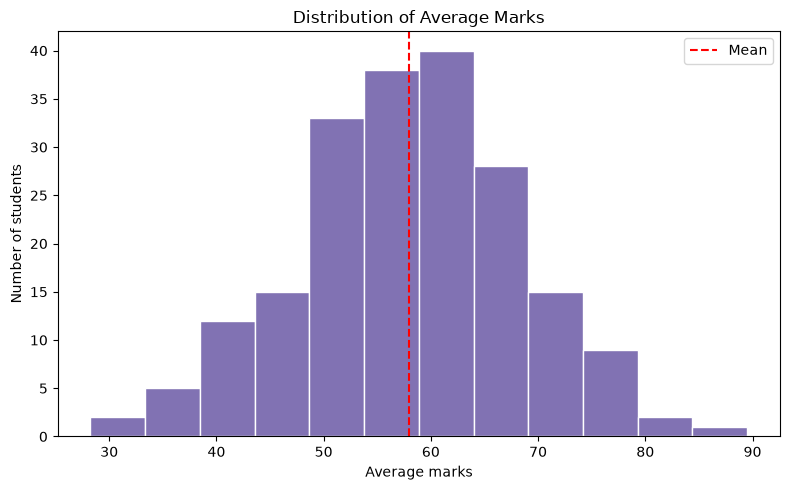

In [30]:
plt.figure(figsize=(8, 5))
plt.hist(df["Average_Marks"], bins=12, color="#8172b3", edgecolor="white")
plt.axvline(df["Average_Marks"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Distribution of Average Marks")
plt.xlabel("Average marks")
plt.ylabel("Number of students")
plt.legend()
plt.tight_layout()
plt.savefig("../Images/05_average_marks_histogram.png", dpi=150)
plt.show()

### Chart 6: Average marks of each section

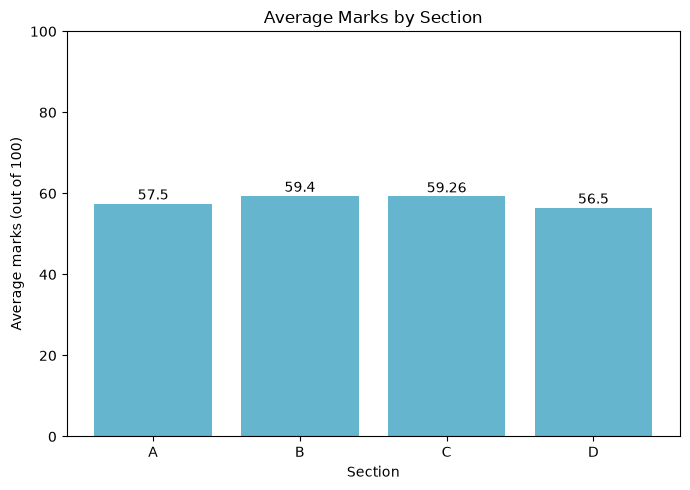

In [31]:
plt.figure(figsize=(7, 5))
plt.bar(section_summary.index, section_summary.values, color="#64b5cd")
plt.title("Average Marks by Section")
plt.xlabel("Section")
plt.ylabel("Average marks (out of 100)")
plt.ylim(0, 100)

for i, v in enumerate(section_summary.values):
    plt.text(i, v + 1, str(v), ha="center")

plt.tight_layout()
plt.savefig("../Images/06_section_average_bar.png", dpi=150)
plt.show()

## Step: Saving the cleaned data and the summary tables

In [32]:
df.to_csv("../Data/Clean_data/student_performance_clean.csv", index=False)

subject_avg.rename("Average_Marks").to_csv("../Reports/subject_average.csv")
result_count.rename("Students").to_csv("../Reports/pass_fail_count.csv")
attendance_summary.to_csv("../Reports/attendance_group_summary.csv")
study_summary.to_csv("../Reports/study_group_summary.csv")
section_summary.rename("Average_Marks").to_csv("../Reports/section_summary.csv")
top_10[["Student_ID", "Section", "Average_Marks", "Result"]].to_csv("../Reports/top_10_students.csv", index=False)
need_support[["Student_ID", "Section", "Attendance_Percentage", "Daily_Study_Hours", "Average_Marks"]].to_csv("../Reports/students_who_failed.csv", index=False)

print("Everything saved")

Everything saved


## My observations
1. **Subjects:** Computer has the highest average (about 62.7) and Science has the lowest (about 53.5). Maths is about 56.1 and English about 59.6. So Science is the subject where students are weakest.
2. **Pass / Fail:** 164 students passed and 36 failed, so the pass percentage is 82%. A student fails if even one subject is below 40.
3. **Attendance:** Students with attendance above 85% have average marks of about 65.4. Students with attendance below 70% have about 53.3. The correlation is about 0.45, which is a moderate positive relation.
4. **Study hours:** Students who study more than 4 hours a day have about 64.2 average marks, and students with less than 2 hours have about 50.0. The correlation is about 0.50, so this also looks like a moderate positive relation.
5. **Section and gender:** The sections are close to each other (about 56.5 to 59.4) and the gender difference is also small (less than 1 mark), so I do not think they matter much in this data.
6. **Data quality:** The raw file had 3 duplicate rows, text inside number columns (`%`, `hrs`, `absent`), wrong spellings in Section and Gender, impossible values (attendance 125, negative study hours, marks 150 and 999) and some missing values. I removed the duplicates, fixed the text, changed impossible values to missing and filled the missing values with median / mode.

## Conclusion
In this project I cleaned a raw student dataset of 203 rows and got 200 clean student records. The analysis shows that students with better attendance and more study hours generally have higher average marks, and Science is the weakest subject for the class. About 18% of the students failed at least one subject.

**Limitations:** the data is made up, the pass rule is my own assumption, and the missing values were filled with the median, which can hide the real values. Also correlation does not prove that attendance or study hours is the *cause* of higher marks. It only shows a relation.

**Suggestions:** the mentors can keep a check on students with attendance below 70%, give extra practice in Science, and give extra support to students in the failed list.

## What I learned
- Reading a csv file and checking it with `head()`, `info()`, `describe()` and `isnull()`
- Cleaning data (duplicates, text mistakes, wrong values, missing values)
- Making new columns and using `groupby()`
- Making bar chart, pie chart, scatter plot and histogram with Matplotlib
- Saving the cleaned data and reports with `to_csv()`